# Feature Engineering v2 — Betty player data

Rebuilds the feature table strictly following the requested 12-group structure.
Input: `Data Science Task Data.xlsx - Result 1.csv` (100,000 players).
Outputs → `features/`:

* `player_features.csv` — the feature table (player_id + 79 features)
* `feature_dictionary.csv` — group / feature / kind / formula / description
* 2 QA charts

Long-form explanations of **every derived feature** (formula, inputs, edge cases)
are in the companion file **`derived_features_explained.md`**.

```
PLAYER
├── 1. LIFECYCLE            registration_date, first_deposit_day, closed_at, status
│                           ★ age, tenure_days, account_lifetime_days, time_to_first_deposit,
│                             is_closed, is_active, days_since_registration
├── 2. ENGAGEMENT           total_logins
│                           ★ login_rate, logins_per_month, login_intensity
├── 3. ECONOMIC / VALUE     total_deposits, total_withdrawals, total_bets, total_wins
│                           ★ net_deposits, withdrawal_ratio, deposit_rate, withdrawal_rate,
│                             betting_rate, winning_rate, bets_to_deposit_ratio,
│                             wins_to_bets_ratio, GGR†, GGR_rate†, GGR_to_deposit_ratio†
├── 4. PLAYER VALUE         ★ deposits_per_login, bets_per_login, wins_per_login,
│                             net_deposit_per_login, betting_intensity, economic_value_per_day
├── 5. ACQUISITION          traffic_source, sub_traffic_source, registration_platform,
│                           utm_source/medium/campaign/content/term, referral_code,
│                           referrer_player_id
│                           ★ referral_flag, paid_acquisition_flag, organic_acquisition_flag,
│                             affiliate_flag, acquisition_channel, campaign_present_flag
├── 6. DEMOGRAPHICS         gender, country, city, occupation
│                           ★ age (shared w/ 1), age_band, occupation_group
├── 7. VIP / COMMERCIAL     vip_level, portfolio_vip_status, player_vip_account_manager,
│                           operational_profit_segment, max_profit_segment_rank
│                           ★ is_vip, vip_status_age_days
├── 8. AML / COMPLIANCE     aml_risk_rating, is_pep, has_sanctions
│                           ★ compliance_risk_flag
├── 9. RESPONSIBLE GAMBLING ever_self_excluded
│                           ★ self_exclusion_flag
├── 10. FRAUD / ABUSE       is_bonus_abuser
│                           ★ bonus_abuse_flag
├── 11. ACCOUNT / PREFS     gaming_level, allow_sms, allow_email, has_mfa_enabled
│                           ★ marketing_contactable, security_enabled
└── 12. EXCLUDED/TECHNICAL  player_id (kept as key), email, phone, names, employer_*,
                            modified_at, loaded_at  — not carried into the table
```

★ = derived · † = conditional (only where source totals exist)

**Conventions**

| Item | Decision |
|---|---|
| `REFERENCE_DATE` | `max(loaded_at)` = **2025-11-13** (data snapshot) |
| `*_rate` (group 3, login_rate) | normalised **per tenure month** (`/ tenure_months`, 30.4375 d) |
| `*_ratio` (group 3) | **amount proportions**, denominator = deposits or bets |
| per-login metrics (group 4) | `/ total_logins` → `NaN` for the 2,273 zero-login players |
| per-day metrics (group 4) | `/ account_lifetime_days` (tenure for open accounts) |
| division by zero | `safe_div` → `NaN`, never `inf` |
| conditional GGR | computed only where `total_bets` **and** `total_wins` are both present (99,786 rows) |
| age | from `birth_date` (not carried); values outside 18–100 → `NaN` (27 rows) |
| aliases | `login_rate` ≡ `logins_per_month` (both names required by the spec) |
| nullable booleans | risk-style flags keep `NaN` = *not recorded*, which is **not** the same as `False` |

In [1]:
%matplotlib inline

import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")

CSV = "Data Science Task Data.xlsx - Result 1.csv"
OUT = "features"
os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(CSV, low_memory=False)

DATE_COLS = ["registration_date", "modified_at", "closed_at", "tc_accepted_date",
             "birth_date", "loaded_at", "vip_status_updated_at", "first_deposit_day"]
for c in DATE_COLS:
    df[c] = pd.to_datetime(df[c], errors="coerce")

REFERENCE_DATE = df["loaded_at"].max()
TENURE_MONTHS = (REFERENCE_DATE - df["registration_date"]).dt.days / 30.4375


def safe_div(num, den):
    # x/0 and 0/0 -> NaN instead of inf
    return num.div(den).replace([np.inf, -np.inf], np.nan)


def as_bool(s):
    # True / False / NaN -> nullable boolean (source columns are object dtype)
    return s.map(lambda v: True if v is True else (False if v is False else pd.NA)
                 ).astype("boolean")


print(f"rows x cols : {df.shape}")
print(f"snapshot    : {REFERENCE_DATE}")

rows x cols : (100000, 77)
snapshot    : 2025-11-13 08:03:42


## 1. LIFECYCLE

**Existing:** `registration_date`, `first_deposit_day`, `closed_at`, `status`

**Derived**

| feature | calculation |
|---|---|
| `age` | `(REFERENCE_DATE − birth_date).days / 365.25`, kept only in [18, 100] |
| `tenure_days` | `(REFERENCE_DATE − registration_date).days` |
| `days_since_registration` | identical to `tenure_days` (alias required by the spec) |
| `account_lifetime_days` | `(closed_at − registration_date).days` if closed, else `tenure_days` |
| `time_to_first_deposit` | calendar-day diff `first_deposit_day − registration_date`; `NaN` if never deposited |
| `is_closed` | `closed_at` present **or** `status` ∈ {Closed, Suspended, SelfExclusion, Timeout, Duplicated} |
| `is_active` | `status == "Approved"` (not a strict complement of `is_closed`: Pending accounts are neither) |

In [2]:
s1 = pd.DataFrame(index=df.index)

# existing
s1["registration_date"] = df["registration_date"]
s1["first_deposit_day"] = df["first_deposit_day"]
s1["closed_at"] = df["closed_at"]
s1["status"] = df["status"]

# derived
age_raw = (REFERENCE_DATE - df["birth_date"]).dt.days / 365.25
s1["age"] = age_raw.where(age_raw.between(18, 100))

s1["tenure_days"] = (REFERENCE_DATE - df["registration_date"]).dt.days
s1["days_since_registration"] = s1["tenure_days"]          # alias

s1["account_lifetime_days"] = (df["closed_at"] - df["registration_date"]).dt.days
s1["account_lifetime_days"] = s1["account_lifetime_days"].fillna(s1["tenure_days"])

s1["time_to_first_deposit"] = (df["first_deposit_day"].dt.normalize() -
                               df["registration_date"].dt.normalize()).dt.days

TERMINAL = ["Closed", "Suspended", "SelfExclusion", "Timeout", "Duplicated"]
s1["is_closed"] = df["closed_at"].notna() | df["status"].isin(TERMINAL)
s1["is_active"] = df["status"].eq("Approved")

display(s1.head(3))
print("is_active :", int(s1.is_active.sum()), "| is_closed:", int(s1.is_closed.sum()))
print("age NaN   :", int(s1.age.isna().sum()),
      "| no first deposit:", int(s1.time_to_first_deposit.isna().sum()))
print("ttfd < 0  :", int((s1.time_to_first_deposit < 0).sum()),
      "(timezone artifact: local-time deposit vs UTC registration)")
print("account_lifetime_days == tenure_days (open):",
      int((s1.account_lifetime_days == s1.tenure_days).sum()))

,registration_date,first_deposit_day,closed_at,status,age,tenure_days,days_since_registration,account_lifetime_days,time_to_first_deposit,is_closed,is_active
0,2025-01-27 13:13:54.535,NaT,NaT,Pending,50.877481,289,289,289.0,NaN,False,False
1,2025-05-19 22:25:56.288,2025-06-11,NaT,Approved,34.483231,177,177,177.0,23.0,False,True
2,2025-07-20 20:52:46.991,2025-07-21,NaT,Approved,28.777550,115,115,115.0,1.0,False,True


is_active : 62654 | is_closed: 21254
age NaN   : 27 | no first deposit: 39933
ttfd < 0  : 12991 (timezone artifact: local-time deposit vs UTC registration)
account_lifetime_days == tenure_days (open): 82241


## 2. ENGAGEMENT / ACTIVITY

**Existing:** `total_logins`

| derived | calculation |
|---|---|
| `login_rate` | `total_logins / tenure_months` (logins per month since registration) |
| `logins_per_month` | alias of `login_rate` |
| `login_intensity` | `total_logins / account_lifetime_days` (logins per day of account life) |

In [3]:
s2 = pd.DataFrame(index=df.index)

s2["total_logins"] = df["total_logins"]
s2["login_rate"] = safe_div(df["total_logins"], TENURE_MONTHS)
s2["logins_per_month"] = s2["login_rate"]                    # alias
s2["login_intensity"] = safe_div(df["total_logins"], s1["account_lifetime_days"])

display(s2.head(3))
print(s2.describe().T.to_string())

,total_logins,login_rate,logins_per_month,login_intensity
0,1.0,0.105320,0.105320,0.003460
1,6.0,1.031780,1.031780,0.033898
2,8.0,2.117391,2.117391,0.069565


                    count        mean         std  min       25%       50%        75%           max
total_logins      99786.0  114.520283  372.429902  0.0  1.000000  3.000000  36.000000  19653.000000
login_rate        99494.0   14.078331   30.550747  0.0  0.207058  0.929389  10.145833    696.377401
logins_per_month  99494.0   14.078331   30.550747  0.0  0.207058  0.929389  10.145833    696.377401
login_intensity   92586.0    0.563341    1.164657  0.0  0.009677  0.047619   0.500000     22.878929


## 3. ECONOMIC / VALUE

**Existing:** `total_deposits`, `total_withdrawals`, `total_bets`, `total_wins`

*Rate* = per tenure month · *Ratio* = amount proportion · † = conditional on source totals

| derived | calculation |
|---|---|
| `net_deposits` | `total_deposits − total_withdrawals` (negative = net withdrawal) |
| `withdrawal_ratio` | `total_withdrawals / total_deposits` (`NaN` if deposits = 0) |
| `deposit_rate` | `total_deposits / tenure_months` |
| `withdrawal_rate` | `total_withdrawals / tenure_months` |
| `betting_rate` | `total_bets / tenure_months` |
| `winning_rate` | `total_wins / tenure_months` |
| `bets_to_deposit_ratio` | `total_bets / total_deposits` (wagering turnover of deposits) |
| `wins_to_bets_ratio` | `total_wins / total_bets` (player win %) |
| `GGR` † | `total_bets − total_wins` where both present |
| `GGR_rate` † | `GGR / tenure_months` |
| `GGR_to_deposit_ratio` † | `GGR / total_deposits` (`NaN` if deposits = 0) |

In [4]:
s3 = pd.DataFrame(index=df.index)

# existing
for c in ["total_deposits", "total_withdrawals", "total_bets", "total_wins"]:
    s3[c] = df[c]

# derived
s3["net_deposits"] = df["total_deposits"] - df["total_withdrawals"]
s3["withdrawal_ratio"] = safe_div(df["total_withdrawals"], df["total_deposits"])
s3["deposit_rate"] = safe_div(df["total_deposits"], TENURE_MONTHS)
s3["withdrawal_rate"] = safe_div(df["total_withdrawals"], TENURE_MONTHS)
s3["betting_rate"] = safe_div(df["total_bets"], TENURE_MONTHS)
s3["winning_rate"] = safe_div(df["total_wins"], TENURE_MONTHS)
s3["bets_to_deposit_ratio"] = safe_div(df["total_bets"], df["total_deposits"])
s3["wins_to_bets_ratio"] = safe_div(df["total_wins"], df["total_bets"])

# conditional GGR: only where both source totals exist
both = df["total_bets"].notna() & df["total_wins"].notna()
s3["GGR"] = (df["total_bets"] - df["total_wins"]).where(both)
s3["GGR_rate"] = safe_div(s3["GGR"], TENURE_MONTHS)
s3["GGR_to_deposit_ratio"] = safe_div(s3["GGR"], df["total_deposits"])

display(s3.head(3))
print(s3.describe().T.to_string())
print()
print("GGR non-null :", int(s3.GGR.notna().sum()), "| GGR < 0:", int((s3.GGR < 0).sum()))
print("net_deposits < 0:", int((s3.net_deposits < 0).sum()))

,total_deposits,total_withdrawals,total_bets,total_wins,net_deposits,withdrawal_ratio,deposit_rate,withdrawal_rate,betting_rate,winning_rate,bets_to_deposit_ratio,wins_to_bets_ratio,GGR,GGR_rate,GGR_to_deposit_ratio
0,0.0,0.0,0.0,0.00,0.0,NaN,0.000000,0.0,0.000000,0.000000,NaN,NaN,0.00,0.000000,NaN
1,20.0,0.0,204.0,164.01,20.0,0.0,3.439266,0.0,35.080508,28.203697,10.2000,0.803971,39.99,6.876811,1.99950
2,40.0,0.0,125.1,70.67,40.0,0.0,10.586957,0.0,33.110707,18.704505,3.1275,0.564908,54.43,14.406201,1.36075


                         count          mean            std            min       25%        50%          75%           max
total_deposits         99786.0   3422.670173   22105.782295       0.000000  0.000000  20.000000   268.000000  2.044597e+06
total_withdrawals      99786.0   2746.757388   18799.760611       0.000000  0.000000   0.000000   145.000000  1.937172e+06
total_bets             99786.0  20166.642330  146873.443475       0.000000  0.000000  40.800000  1239.745000  1.334522e+07
total_wins             99786.0  19114.728724  140422.190007       0.000000  0.000000  25.820000  1072.915000  1.285009e+07
net_deposits           99786.0    675.912785    5017.448526 -138459.550000  0.000000   0.000000    56.000000  3.633670e+05
withdrawal_ratio       60068.0      0.869951       1.607395       0.000000  0.000000   0.703945     1.119572  1.280000e+02
deposit_rate           99494.0    387.768066    2152.565733       0.000000  0.000000   4.085570    67.638889  1.559710e+05
withdrawal_rate 

## 4. PLAYER VALUE / INTENSITY

All per-login metrics: `NaN` when `total_logins = 0` (2,273 players).

| derived | calculation |
|---|---|
| `deposits_per_login` | `total_deposits / total_logins` |
| `bets_per_login` | `total_bets / total_logins` |
| `wins_per_login` | `total_wins / total_logins` |
| `net_deposit_per_login` | `net_deposits / total_logins` |
| `betting_intensity` | `total_bets / account_lifetime_days` (bets per day of account life) |
| `economic_value_per_day` | `GGR / account_lifetime_days` (operator revenue per day) |

In [5]:
s4 = pd.DataFrame(index=df.index)

s4["deposits_per_login"] = safe_div(s3["total_deposits"], s2["total_logins"])
s4["bets_per_login"] = safe_div(s3["total_bets"], s2["total_logins"])
s4["wins_per_login"] = safe_div(s3["total_wins"], s2["total_logins"])
s4["net_deposit_per_login"] = safe_div(s3["net_deposits"], s2["total_logins"])
s4["betting_intensity"] = safe_div(s3["total_bets"], s1["account_lifetime_days"])
s4["economic_value_per_day"] = safe_div(s3["GGR"], s1["account_lifetime_days"])

display(s4.head(3))
print(s4.describe().T.to_string())

,deposits_per_login,bets_per_login,wins_per_login,net_deposit_per_login,betting_intensity,economic_value_per_day
0,0.000000,0.0000,0.00000,0.000000,0.000000,0.000000
1,3.333333,34.0000,27.33500,3.333333,1.152542,0.225932
2,5.000000,15.6375,8.83375,5.000000,1.087826,0.473304


                          count        mean         std       min  25%       50%        75%           max
deposits_per_login      97513.0   20.544640  117.059134     0.000  0.0  2.918455  13.750000   21000.00000
bets_per_login          97513.0  104.472183  718.022008     0.000  0.0  6.735193  49.900000   71207.70000
wins_per_login          97513.0   93.890837  667.426152     0.000  0.0  4.484000  40.402308   68405.16375
net_deposit_per_login   97513.0    7.913919  104.255504 -5624.020  0.0  0.000000   4.000000   21000.00000
betting_intensity       92586.0   97.704881  806.494604     0.000  0.0  0.432308  14.359256  143857.53000
economic_value_per_day  92586.0    5.623259   66.709755 -9848.645  0.0  0.030289   1.354995    6765.82000


## 5. ACQUISITION

**Existing:** `traffic_source`, `sub_traffic_source`, `registration_platform`,
`utm_source`, `utm_medium`, `utm_campaign`, `utm_content`, `utm_term`,
`referral_code`, `referrer_player_id`

`acquisition_channel` is mapped first, then the flags are derived from it:

| channel | sources |
|---|---|
| Paid Search | Google, Google_vpr, Google_vpr_cad, Microsoft |
| Paid Social | Facebook, TikTok, Snapchat, Instagram, Twitter, Reddit, Apple Ads |
| Paid Display/UA | Liftoff, Moloco, Criteo, Adform, DV 360, Gumgum, Local Publisher |
| Organic | Organic, Organic Social |
| Referral | Referred, Referred From Paid Traffic |
| Direct/Brand | betty.com, Brand, Web to App |
| Unknown | Unclassified UTM, Unknown, Scenarios, *(missing)*, anything else |

| derived | calculation |
|---|---|
| `referral_flag` | `referral_code` or `referrer_player_id` present |
| `paid_acquisition_flag` | channel ∈ Paid Search/Social/Display |
| `organic_acquisition_flag` | channel == Organic |
| `affiliate_flag` | `btag` present or an explicit "affiliate" marker — **only 3 rows exist**; this dataset has no real affiliate traffic |
| `campaign_present_flag` | `utm_campaign` present |

In [6]:
s5 = pd.DataFrame(index=df.index)

# existing
for c in ["traffic_source", "sub_traffic_source", "registration_platform",
          "utm_source", "utm_medium", "utm_campaign", "utm_content", "utm_term",
          "referral_code", "referrer_player_id"]:
    s5[c] = df[c]

# derived ---------------------------------------------------------------
CHANNEL_MAP = {}
for c in ["Google", "Google_vpr", "Google_vpr_cad", "Microsoft"]:
    CHANNEL_MAP[c] = "Paid Search"
for c in ["Facebook", "TikTok", "Snapchat", "Instagram", "Twitter", "Reddit",
          "Apple Ads"]:
    CHANNEL_MAP[c] = "Paid Social"
for c in ["Liftoff", "Moloco", "Criteo", "Adform", "DV 360", "Gumgum",
          "Local Publisher"]:
    CHANNEL_MAP[c] = "Paid Display/UA"
for c in ["Organic", "Organic Social"]:
    CHANNEL_MAP[c] = "Organic"
for c in ["Referred", "Referred From Paid Traffic"]:
    CHANNEL_MAP[c] = "Referral"
for c in ["betty.com", "Brand", "Web to App"]:
    CHANNEL_MAP[c] = "Direct/Brand"

s5["acquisition_channel"] = df["traffic_source"].map(CHANNEL_MAP).fillna("Unknown")

PAID = ["Paid Search", "Paid Social", "Paid Display/UA"]
s5["paid_acquisition_flag"] = s5["acquisition_channel"].isin(PAID)
s5["organic_acquisition_flag"] = s5["acquisition_channel"].eq("Organic")
s5["referral_flag"] = (df["referral_code"].notna() |
                       df["referrer_player_id"].notna())
affiliate_marker = (df["btag"].notna() |
                    df["traffic_source"].fillna("").str.contains("affiliate", case=False) |
                    df["utm_source"].fillna("").str.contains("affiliate", case=False))
s5["affiliate_flag"] = affiliate_marker
s5["campaign_present_flag"] = df["utm_campaign"].notna()

display(s5.head(3))
print(s5["acquisition_channel"].value_counts().to_string())
for c in ["referral_flag", "paid_acquisition_flag", "organic_acquisition_flag",
          "affiliate_flag", "campaign_present_flag"]:
    print(f"{c:28} True = {int(s5[c].sum()):>6}")

,traffic_source,sub_traffic_source,registration_platform,utm_source,utm_medium,utm_campaign,utm_content,utm_term,referral_code,referrer_player_id,acquisition_channel,paid_acquisition_flag,organic_acquisition_flag,referral_flag,affiliate_flag,campaign_present_flag
0,Organic,Organic,Web,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Organic,False,True,False,False,False
1,Organic,Organic,iOS App,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Organic,False,True,False,False,False
2,Referred,Referred,Web,NaN,NaN,NaN,NaN,NaN,andrewsl28atat,7089980.0,Referral,False,False,True,False,False


acquisition_channel
Paid Search        27641
Organic            26881
Referral           24232
Paid Social        12516
Paid Display/UA     5723
Unknown             2662
Direct/Brand         345
referral_flag                True =  25881
paid_acquisition_flag        True =  45880
organic_acquisition_flag     True =  26881
affiliate_flag               True =      3
campaign_present_flag        True =  35897


## 6. DEMOGRAPHICS

**Existing:** `gender`, `country`, `city`, `occupation`
(`birth_date` is the *source* for `age` and is not carried.)

| derived | calculation |
|---|---|
| `age` | shared with group 1 — single physical column |
| `age_band` | 18-24 / 25-34 / 35-44 / 45-54 / 55-64 / 65+ from `age`; `Unknown` if age is `NaN` |
| `occupation_group` | `occupation` lower-cased and stripped of non-letters must **equal** `student` / `retired` / `unemployed` / `homemaker` to land in that group (catches "Home maker", "retired"); any other value = a job title → **Employed**; missing → Unknown |

In [7]:
s6 = pd.DataFrame(index=df.index)

s6["gender"] = df["gender"]
s6["country"] = df["country"]
s6["city"] = df["city"]
s6["occupation"] = df["occupation"]

# derived
s6["age_band"] = pd.cut(s1["age"],
                        bins=[18, 25, 35, 45, 55, 65, 120],
                        labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
                        right=False).astype("object")
s6.loc[s6["age_band"].isna() & s1["age"].isna(), "age_band"] = "Unknown"

oc = (df["occupation"].fillna("").str.lower()
      .str.replace(r"[^a-z]", "", regex=True))
GROUPS4 = {"student": "Student", "retired": "Retired",
           "unemployed": "Unemployed", "homemaker": "Homemaker"}
grp = pd.Series("Employed", index=df.index, dtype="object")
grp[oc.isin(GROUPS4)] = oc[oc.isin(GROUPS4)].map(GROUPS4)
grp[df["occupation"].isna()] = "Unknown"
s6["occupation_group"] = grp

display(s6.head(3))
print(s6["age_band"].value_counts().to_string())
print()
print(s6["occupation_group"].value_counts().to_string())

,gender,country,city,occupation,age_band,occupation_group
0,Female,Canada,St Thomas,Homemaker,45-54,Homemaker
1,Male,Canada,Hamilton,Manufacturing Machine Operator,25-34,Employed
2,Female,Canada,Brantford,Unemployed,25-34,Unemployed


age_band
25-34      27202
35-44      21874
18-24      19877
45-54      15689
55-64      10240
65+         5091
Unknown       27

occupation_group
Employed      58181
Unemployed    14438
Student       11949
Retired        8697
Homemaker      6734
Unknown           1


## 7. VIP / COMMERCIAL

**Existing:** `vip_level`, `portfolio_vip_status`, `player_vip_account_manager`,
`operational_profit_segment`, `max_profit_segment_rank`

| derived | calculation |
|---|---|
| `is_vip` | `vip_level` present **or** `portfolio_vip_status == "Enabled"` **or** `operational_profit_segment ∈ {Vip1, Vip2, Vip3}` |
| `vip_status_age_days` | `(REFERENCE_DATE − vip_status_updated_at).days` — `NaN` for the 99.6% without VIP status |

In [8]:
s7 = pd.DataFrame(index=df.index)

for c in ["vip_level", "portfolio_vip_status", "player_vip_account_manager",
          "operational_profit_segment", "max_profit_segment_rank"]:
    s7[c] = df[c]

s7["is_vip"] = (df["vip_level"].notna() |
                df["portfolio_vip_status"].eq("Enabled") |
                df["operational_profit_segment"].isin(["Vip1", "Vip2", "Vip3"]))
s7["vip_status_age_days"] = (REFERENCE_DATE - df["vip_status_updated_at"]).dt.days

display(s7.head(3))
print("is_vip:", int(s7.is_vip.sum()),
      "| vip_status_age_days non-null:", int(s7.vip_status_age_days.notna().sum()))
print(s7["operational_profit_segment"].value_counts(dropna=False).to_string())

,vip_level,portfolio_vip_status,player_vip_account_manager,operational_profit_segment,max_profit_segment_rank,is_vip,vip_status_age_days
0,NaN,NaN,NaN,LowValue,100300.0,False,NaN
1,NaN,NaN,NaN,LowValue,100300.0,False,NaN
2,NaN,NaN,NaN,LowValue,100300.0,False,NaN


is_vip: 5521 | vip_status_age_days non-null: 358
operational_profit_segment
LowValue         57977
NegativeValue    23292
MediumValue       5366
Toddler           5241
HighValue         2783
Vip1              2675
Vip2              1337
Vip3              1321
NaN                  8


## 8. AML / COMPLIANCE

**Existing:** `aml_risk_rating`, `is_pep`, `has_sanctions`

| derived | calculation |
|---|---|
| `compliance_risk_flag` | **True** if AML ∈ {High, Extreme} **or** PEP **or** sanctions; **False** if AML ∈ {Low, Moderate} and neither PEP nor sanctions; **`NaN`** if AML rating is missing and neither PEP nor sanctions (unknown ≠ clean) |

In [9]:
s8 = pd.DataFrame(index=df.index)

s8["aml_risk_rating"] = df["aml_risk_rating"]
s8["is_pep"] = df["is_pep"]
s8["has_sanctions"] = df["has_sanctions"]

high = df["aml_risk_rating"].isin(["High", "Extreme"])
lowish = df["aml_risk_rating"].isin(["Low", "Moderate"])
other = df["aml_risk_rating"].isna()
pep_or_sanctions = df["is_pep"] | df["has_sanctions"]

flag = pd.Series(pd.NA, index=df.index, dtype="boolean")
flag[lowish & ~pep_or_sanctions] = False
flag[high | pep_or_sanctions] = True
flag[other & ~pep_or_sanctions] = pd.NA
s8["compliance_risk_flag"] = flag

display(s8.head(3))
print("compliance_risk_flag:", s8["compliance_risk_flag"].value_counts(dropna=False).to_dict())

,aml_risk_rating,is_pep,has_sanctions,compliance_risk_flag
0,Low,True,False,True
1,Low,False,False,False
2,Low,False,False,False


compliance_risk_flag: {np.False_: 97455, <NA>: 2136, np.True_: 409}


## 9. RESPONSIBLE GAMBLING

**Existing:** `ever_self_excluded` (True 2.1% / False 51.4% / not recorded 46.5%)

| derived | calculation |
|---|---|
| `self_exclusion_flag` | **True** if `ever_self_excluded` is True **or** `status == "SelfExclusion"`; **False** if recorded False; **`NaN`** where the source never recorded it |

In [10]:
s9 = pd.DataFrame(index=df.index)

s9["ever_self_excluded"] = df["ever_self_excluded"]
se = as_bool(df["ever_self_excluded"])
s9["self_exclusion_flag"] = (se.eq(True) | df["status"].eq("SelfExclusion")
                             ).astype("boolean")

display(s9.head(3))
print("source   :", df["ever_self_excluded"].value_counts(dropna=False).to_dict())
print("derived  :", s9["self_exclusion_flag"].value_counts(dropna=False).to_dict())
print("added by status=SelfExclusion:",
      int((s9.self_exclusion_flag.eq(True) & se.ne(True).fillna(True)).sum()))

,ever_self_excluded,self_exclusion_flag
0,NaN,<NA>
1,False,False
2,False,False


source   : {False: 51351, nan: 46518, True: 2131}
derived  : {np.False_: 51351, <NA>: 46518, np.True_: 2131}


added by status=SelfExclusion: 0


## 10. FRAUD / ABUSE

**Existing:** `is_bonus_abuser` (True 5.0% / False 1.0% / not recorded 94.0%)

| derived | calculation |
|---|---|
| `bonus_abuse_flag` | `is_bonus_abuser` normalised to a nullable boolean — **`NaN` means "not assessed"**, not "not an abuser" |

In [11]:
s10 = pd.DataFrame(index=df.index)

s10["is_bonus_abuser"] = df["is_bonus_abuser"]
s10["bonus_abuse_flag"] = as_bool(df["is_bonus_abuser"])

display(s10.head(3))
print("source :", df["is_bonus_abuser"].value_counts(dropna=False).to_dict())
print("derived:", s10["bonus_abuse_flag"].value_counts(dropna=False).to_dict())

,is_bonus_abuser,bonus_abuse_flag
0,NaN,<NA>
1,NaN,<NA>
2,NaN,<NA>


source : {nan: 94026, True: 4965, False: 1009}
derived: {<NA>: 94026, np.True_: 4965, np.False_: 1009}


## 11. ACCOUNT / PREFERENCES

**Existing:** `gaming_level`, `allow_sms`, `allow_email`, `has_mfa_enabled`

| derived | calculation |
|---|---|
| `marketing_contactable` | `allow_sms OR allow_email` (Kleene logic: `True OR NaN = True`, `False OR NaN = NaN`) |
| `security_enabled` | `has_mfa_enabled` normalised to nullable boolean (18.5% not recorded) |

In [12]:
s11 = pd.DataFrame(index=df.index)

s11["gaming_level"] = df["gaming_level"]
s11["allow_sms"] = df["allow_sms"]
s11["allow_email"] = df["allow_email"]
s11["has_mfa_enabled"] = df["has_mfa_enabled"]

sms = as_bool(df["allow_sms"])
email = as_bool(df["allow_email"])
s11["marketing_contactable"] = (sms | email).astype("boolean")
s11["security_enabled"] = as_bool(df["has_mfa_enabled"])

display(s11.head(3))
print("marketing_contactable:", s11["marketing_contactable"].value_counts(dropna=False).to_dict())
print("security_enabled     :", s11["security_enabled"].value_counts(dropna=False).to_dict())

,gaming_level,allow_sms,allow_email,has_mfa_enabled,marketing_contactable,security_enabled
0,Experienced,True,True,False,True,False
1,Experienced,False,False,False,False,False
2,Experienced,True,True,False,True,False


marketing_contactable: {np.True_: 69500, np.False_: 30145, <NA>: 355}
security_enabled     : {np.False_: 80080, <NA>: 18532, np.True_: 1388}


## 12. EXCLUDED / TECHNICAL

`player_id` is kept as the **key** of the feature table; the remaining columns are
**not carried** into `player_features.csv`:

`email`, `phone_number`, `first_name`, `middle_name`, `last_name`,
`employer_name`, `employer_city`, `employer_country`, `employer_postal_code`,
`employer_phone_number`, `modified_at`, `loaded_at`

(PII / employer fields ~99% missing / technical timestamps — they are listed in
the feature dictionary with kind `excluded` for traceability.)

In [13]:
EXCLUDED = ["player_id", "email", "phone_number", "first_name", "middle_name",
            "last_name", "employer_name", "employer_city", "employer_country",
            "employer_postal_code", "employer_phone_number", "modified_at",
            "loaded_at"]

present = [c for c in EXCLUDED if c in df.columns]
missing = [c for c in EXCLUDED if c not in df.columns]
print("present in source:", present)
print("not found        :", missing)
print()
print("missing % of excluded source columns:")
print((df[present].isna().mean() * 100).round(2).to_string())
print("\nplayer_id is retained as the feature-table key; the rest are dropped.")

present in source: ['player_id', 'email', 'phone_number', 'first_name', 'middle_name', 'last_name', 'employer_name', 'employer_city', 'employer_country', 'employer_postal_code', 'employer_phone_number', 'modified_at', 'loaded_at']
not found        : []

missing % of excluded source columns:
player_id                 0.00
email                     0.00
phone_number              0.00
first_name                0.00
middle_name               0.00
last_name                 0.00
employer_name            99.07
employer_city            99.40
employer_country         99.40
employer_postal_code     99.56
employer_phone_number    99.70
modified_at               0.00
loaded_at                 0.00

player_id is retained as the feature-table key; the rest are dropped.


## Assembly — `player_features` + `feature_dictionary`

Column order follows the 12-group structure. `age` appears once (group 1) and is
listed under both groups 1 and 6 in the dictionary.

In [14]:
GROUPS = [
    ("1. Lifecycle", s1),
    ("2. Engagement / Activity", s2),
    ("3. Economic / Value", s3),
    ("4. Player Value / Intensity", s4),
    ("5. Acquisition", s5),
    ("6. Demographics", s6),
    ("7. VIP / Commercial", s7),
    ("8. AML / Compliance", s8),
    ("9. Responsible Gambling", s9),
    ("10. Fraud / Abuse", s10),
    ("11. Account / Preferences", s11),
]

player_features = pd.concat([df[["player_id"]]] + [g for _, g in GROUPS], axis=1)
player_features = player_features.loc[:, ~player_features.columns.duplicated()]

assert player_features.columns.is_unique
assert len(player_features) == 100_000
print(f"player_features: {player_features.shape[0]} rows x "
      f"{player_features.shape[1]} cols (incl. player_id)")

# ---------------- feature dictionary --------------------------------------
D = []


def add(group, feature, kind, formula):
    D.append({"group": group, "feature": feature, "kind": kind, "formula": formula})


G = "1. Lifecycle"
add(G, "registration_date", "existing", "source")
add(G, "first_deposit_day", "existing", "source")
add(G, "closed_at", "existing", "source")
add(G, "status", "existing", "source")
add(G, "age", "derived", "(REFERENCE_DATE - birth_date).days / 365.25, kept in [18,100]")
add(G, "tenure_days", "derived", "(REFERENCE_DATE - registration_date).days")
add(G, "days_since_registration", "derived", "alias of tenure_days")
add(G, "account_lifetime_days", "derived", "(closed_at - registration_date).days, else tenure_days")
add(G, "time_to_first_deposit", "derived", "first_deposit_day - registration_date (calendar days)")
add(G, "is_closed", "derived", "closed_at present OR status in terminal states")
add(G, "is_active", "derived", "status == 'Approved'")

G = "2. Engagement / Activity"
add(G, "total_logins", "existing", "source")
add(G, "login_rate", "derived", "total_logins / tenure_months")
add(G, "logins_per_month", "derived", "alias of login_rate")
add(G, "login_intensity", "derived", "total_logins / account_lifetime_days")

G = "3. Economic / Value"
add(G, "total_deposits", "existing", "source")
add(G, "total_withdrawals", "existing", "source")
add(G, "total_bets", "existing", "source")
add(G, "total_wins", "existing", "source")
add(G, "net_deposits", "derived", "total_deposits - total_withdrawals")
add(G, "withdrawal_ratio", "derived", "total_withdrawals / total_deposits")
add(G, "deposit_rate", "derived", "total_deposits / tenure_months")
add(G, "withdrawal_rate", "derived", "total_withdrawals / tenure_months")
add(G, "betting_rate", "derived", "total_bets / tenure_months")
add(G, "winning_rate", "derived", "total_wins / tenure_months")
add(G, "bets_to_deposit_ratio", "derived", "total_bets / total_deposits")
add(G, "wins_to_bets_ratio", "derived", "total_wins / total_bets")
add(G, "GGR", "derived (conditional)", "total_bets - total_wins (both present)")
add(G, "GGR_rate", "derived (conditional)", "GGR / tenure_months")
add(G, "GGR_to_deposit_ratio", "derived (conditional)", "GGR / total_deposits")

G = "4. Player Value / Intensity"
add(G, "deposits_per_login", "derived", "total_deposits / total_logins")
add(G, "bets_per_login", "derived", "total_bets / total_logins")
add(G, "wins_per_login", "derived", "total_wins / total_logins")
add(G, "net_deposit_per_login", "derived", "net_deposits / total_logins")
add(G, "betting_intensity", "derived", "total_bets / account_lifetime_days")
add(G, "economic_value_per_day", "derived", "GGR / account_lifetime_days")

G = "5. Acquisition"
for c in ["traffic_source", "sub_traffic_source", "registration_platform",
          "utm_source", "utm_medium", "utm_campaign", "utm_content", "utm_term",
          "referral_code", "referrer_player_id"]:
    add(G, c, "existing", "source")
add(G, "referral_flag", "derived", "referral_code or referrer_player_id present")
add(G, "paid_acquisition_flag", "derived", "acquisition_channel starts with 'Paid'")
add(G, "organic_acquisition_flag", "derived", "acquisition_channel == 'Organic'")
add(G, "affiliate_flag", "derived", "btag present or 'affiliate' marker (3 rows)")
add(G, "acquisition_channel", "derived", "channel mapping of traffic_source (7 classes)")
add(G, "campaign_present_flag", "derived", "utm_campaign present")

G = "6. Demographics"
for c in ["gender", "country", "city", "occupation"]:
    add(G, c, "existing", "source")
add(G, "age", "shared", "same column as group 1")
add(G, "age_band", "derived", "binning of age: 18-24 / 25-34 / ... / 65+ / Unknown")
add(G, "occupation_group", "derived", "normalized exact match -> Student/Retired/Unemployed/Homemaker, else Employed, NA -> Unknown")

G = "7. VIP / Commercial"
for c in ["vip_level", "portfolio_vip_status", "player_vip_account_manager",
          "operational_profit_segment", "max_profit_segment_rank"]:
    add(G, c, "existing", "source")
add(G, "is_vip", "derived", "vip_level present OR status Enabled OR segment in Vip1-3")
add(G, "vip_status_age_days", "derived", "(REFERENCE_DATE - vip_status_updated_at).days")

G = "8. AML / Compliance"
for c in ["aml_risk_rating", "is_pep", "has_sanctions"]:
    add(G, c, "existing", "source")
add(G, "compliance_risk_flag", "derived", "AML in High/Extreme OR PEP OR sanctions; NA if rating missing")

G = "9. Responsible Gambling"
add(G, "ever_self_excluded", "existing", "source")
add(G, "self_exclusion_flag", "derived", "ever_self_excluded OR status == 'SelfExclusion'; NA if unrecorded")

G = "10. Fraud / Abuse"
add(G, "is_bonus_abuser", "existing", "source")
add(G, "bonus_abuse_flag", "derived", "is_bonus_abuser as nullable boolean; NA = not assessed")

G = "11. Account / Preferences"
for c in ["gaming_level", "allow_sms", "allow_email", "has_mfa_enabled"]:
    add(G, c, "existing", "source")
add(G, "marketing_contactable", "derived", "allow_sms OR allow_email (Kleene)")
add(G, "security_enabled", "derived", "has_mfa_enabled as nullable boolean")

G = "12. Excluded / Technical"
for c in EXCLUDED:
    add(G, c, "excluded" if c != "player_id" else "key", "not carried (player_id = table key)")

feature_dictionary = pd.DataFrame(D, columns=["group", "feature", "kind", "formula"])
print(f"dictionary: {len(feature_dictionary)} rows -> "
      f"{feature_dictionary['kind'].value_counts().to_dict()}")

# ---------------- printed tree --------------------------------------------
MARK = {"existing": " ", "derived": "★", "derived (conditional)": "★†",
        "shared": "◆", "excluded": "×", "key": "•"}
seen = set()
print("\nPLAYER")
for gname, _ in GROUPS + [("12. Excluded / Technical", None)]:
    rows = feature_dictionary[feature_dictionary.group == gname]
    print(f"├── {gname}")
    for i, (_, r) in enumerate(rows.iterrows()):
        branch = "└──" if i == len(rows) - 1 else "├──"
        dup = " (see group 1)" if r.feature in seen and r.kind == "shared" else ""
        seen.add(r.feature)
        print(f"│   {branch} {r.feature:<28} {MARK[r.kind]}{dup}")

# ---------------- save -----------------------------------------------------
player_features.to_csv(f"{OUT}/player_features.csv", index=False)
feature_dictionary.to_csv(f"{OUT}/feature_dictionary.csv", index=False)
print(f"\n[saved] {OUT}/player_features.csv")
print(f"[saved] {OUT}/feature_dictionary.csv")

player_features: 100000 rows x 80 cols (incl. player_id)
dictionary: 93 rows -> {'derived': 39, 'existing': 37, 'excluded': 12, 'derived (conditional)': 3, 'shared': 1, 'key': 1}

PLAYER
├── 1. Lifecycle
│   ├── registration_date             
│   ├── first_deposit_day             
│   ├── closed_at                     
│   ├── status                        
│   ├── age                          ★
│   ├── tenure_days                  ★
│   ├── days_since_registration      ★
│   ├── account_lifetime_days        ★
│   ├── time_to_first_deposit        ★
│   ├── is_closed                    ★
│   └── is_active                    ★
├── 2. Engagement / Activity
│   ├── total_logins                  
│   ├── login_rate                   ★
│   ├── logins_per_month             ★
│   └── login_intensity              ★
├── 3. Economic / Value
│   ├── total_deposits                
│   ├── total_withdrawals             
│   ├── total_bets                    
│   ├── total_wins                    
│ 


[saved] features/player_features.csv
[saved] features/feature_dictionary.csv


## QA — validation checks, missingness, distributions, correlations

rows x cols      : (100000, 80)
unique columns   : True
inf values       : 0  (must be 0)

  is_active                        62654
  is_closed                        21254
  age NaN (cleaned)                   27
  GGR non-null                     99786
  GGR < 0 (player up)               7577
  net_deposits < 0                 18159
  withdrawal_ratio > 1             18061
  zero-deposit -> NaN ratio        39932
  zero-login -> NaN per_login       2487
  is_vip                            5521
  compliance_risk True               409
  self_exclusion True               2131
  bonus_abuse True                  4965
  referral_flag                    25881
  paid_acquisition                 45880
  organic_acquisition              26881
  affiliate_flag                       3
  marketing_contactable True       69500
  security_enabled True             1388

missing % of derived features:
vip_status_age_days       99.64
bonus_abuse_flag          94.03
self_exclusion_flag       46.52
wi

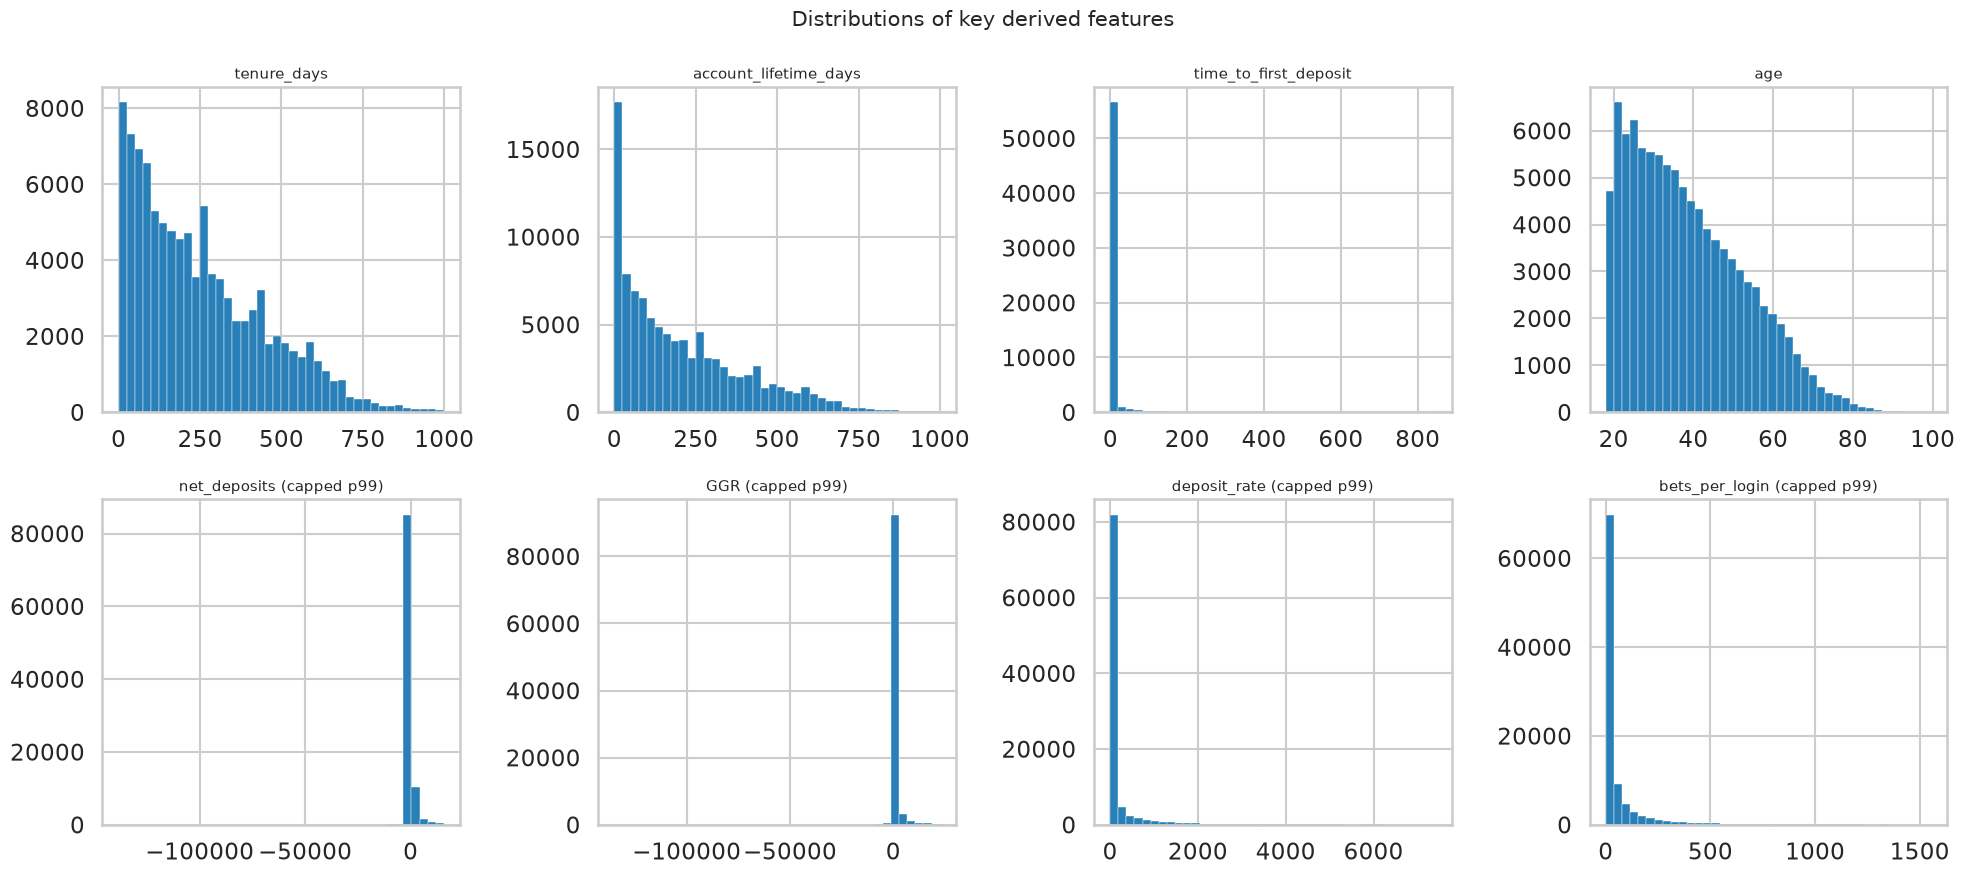

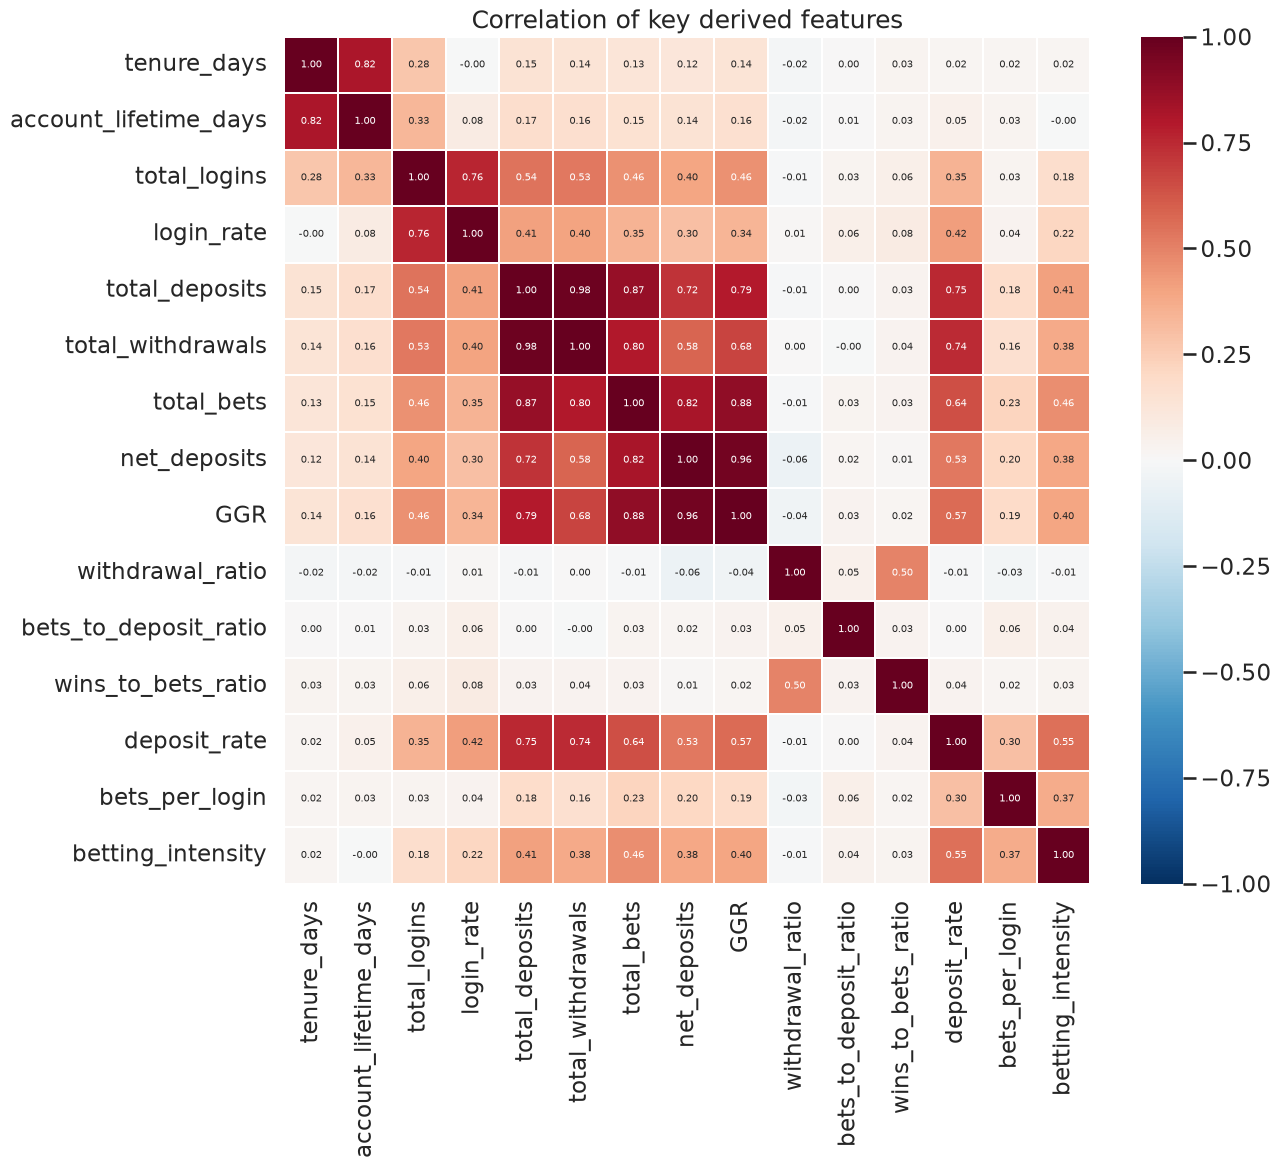


[saved] features/derived_feature_distributions.png
[saved] features/derived_feature_correlations.png
Done.


In [15]:
# --- integrity ------------------------------------------------------------
num = player_features.select_dtypes("number").columns
arr = player_features[num].to_numpy(dtype=float, na_value=np.nan)
print(f"rows x cols      : {player_features.shape}")
print(f"unique columns   : {player_features.columns.is_unique}")
print(f"inf values       : {int(np.isinf(arr).sum())}  (must be 0)")

derived_cols = feature_dictionary[feature_dictionary.kind.str.startswith("derived")]["feature"]
derived_cols = [c for c in derived_cols.unique() if c in player_features.columns]

checks = {
    "is_active": int(player_features.is_active.sum()),
    "is_closed": int(player_features.is_closed.sum()),
    "age NaN (cleaned)": int(player_features.age.isna().sum()),
    "GGR non-null": int(player_features.GGR.notna().sum()),
    "GGR < 0 (player up)": int((player_features.GGR < 0).sum()),
    "net_deposits < 0": int((player_features.net_deposits < 0).sum()),
    "withdrawal_ratio > 1": int((player_features.withdrawal_ratio > 1).sum()),
    "zero-deposit -> NaN ratio": int(player_features.bets_to_deposit_ratio.isna().sum()),
    "zero-login -> NaN per_login": int(player_features.bets_per_login.isna().sum()),
    "is_vip": int(player_features.is_vip.sum()),
    "compliance_risk True": int(player_features.compliance_risk_flag.eq(True).sum()),
    "self_exclusion True": int(player_features.self_exclusion_flag.eq(True).sum()),
    "bonus_abuse True": int(player_features.bonus_abuse_flag.eq(True).sum()),
    "referral_flag": int(player_features.referral_flag.sum()),
    "paid_acquisition": int(player_features.paid_acquisition_flag.sum()),
    "organic_acquisition": int(player_features.organic_acquisition_flag.sum()),
    "affiliate_flag": int(player_features.affiliate_flag.sum()),
    "marketing_contactable True": int(player_features.marketing_contactable.eq(True).sum()),
    "security_enabled True": int(player_features.security_enabled.eq(True).sum()),
}
print()
for k, v in checks.items():
    print(f"  {k:<30} {v:>7}")

# --- missingness of derived features --------------------------------------
miss = (player_features[derived_cols].isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print("\nmissing % of derived features:")
print(miss.to_string() if len(miss) else "  (none)")

# --- distributions ---------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
specs = [("tenure_days", None), ("account_lifetime_days", None),
         ("time_to_first_deposit", None), ("age", None),
         ("net_deposits", 0.99), ("GGR", 0.99),
         ("deposit_rate", 0.99), ("bets_per_login", 0.99)]
for ax, (c, q) in zip(axes.ravel(), specs):
    s = player_features[c].dropna()
    if q:
        s = s[s <= s.quantile(q)]
    ax.hist(s, bins=40, color="#2980b9", edgecolor="white", linewidth=0.3)
    ax.set_title(c + (f" (capped p{int(q*100)})" if q else ""), fontsize=11)
fig.suptitle("Distributions of key derived features", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/derived_feature_distributions.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)

# --- correlations ----------------------------------------------------------
key = ["tenure_days", "account_lifetime_days", "total_logins", "login_rate",
       "total_deposits", "total_withdrawals", "total_bets", "net_deposits",
       "GGR", "withdrawal_ratio", "bets_to_deposit_ratio", "wins_to_bets_ratio",
       "deposit_rate", "bets_per_login", "betting_intensity"]
corr = player_features[key].corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True,
            fmt=".2f", linewidths=0.3, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation of key derived features")
fig.savefig(f"{OUT}/derived_feature_correlations.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)

print(f"\n[saved] {OUT}/derived_feature_distributions.png")
print(f"[saved] {OUT}/derived_feature_correlations.png")
print("Done.")